# ====================================================
# **DERIVING SPATIAL MAPS WITH HYDROMT-WFLOW IN PYTHON**
# ====================================================

## **=== Importing relevant packages ===**


In [1]:
print("=== Please run julia WflowRaster.ipynb")

# from hydromt_wflow import WflowSbmModel
# import hydromt_wflow
from hydromt.gis import flw
from matplotlib import cm, colors
from pyflwdir.core_conversion import d8_to_ldd
import geopandas as gpd
import hydromt
import matplotlib.pyplot as plt
import numpy as np
import os as os
import pyflwdir
import rioxarray as rxr
import xarray


=== Please run julia WflowRaster.ipynb


# === **PARAMETERS** ===

In [ ]:
# <"Timoleague">; <"Ballycanew">; <"Castledockerell">; <"Corduff">; <"Dunleer">; <"Cregduff">
Flag_CatchmentName = "Timoleague"

# ======= PATHS =======
Path_Root_Data = "D:/JOE/MAIN/MODELS/WFLOW/DATA"
Path_Root = os.path.join(Path_Root_Data, "CATCHMENTS", Flag_CatchmentName)

# Path_Gis = "InputGis"
Path_Julia  = "OutputJulia"
Path_Python = "OutputPython"
Path_River  = "RIVERS"

# == Input ==
Filename_Input_RiverShp = "RiversIreland.gdb"
Filename_Input_DtmJulia = "Ireland_DEM_Croped.tiff"

# == Output ==
Filename_DtmCorrected         = "DtmCorrected"
Filename_Floodplains          = "Floodplains"
Filename_Ldd                  = "Ldd"
Filename_RiverLength          = "RiverLength"
Filename_StreamOrder           = "StreamOrder"
Filename_Slope                = "Slope"
Filename_Subcatchment = "CatchmentSubcatchment"

# == Parameters ==
# Param_NoData      = 255  # Not yet applicable
Param_Crs         = 29902  # [-] This is the default projection TM65 / Irish Grid
Param_PitMaxDepth = -1.0
Param_RiverDepth  = 5 # if Flag_BurnRiver (float) – fixed depth value used to burn in the dtm

# == Flags ==
Flag_BassinCatchment = True
Flag_Plot      = True
Flag_BurnRiver = True


## == *Timoleague* ==


In [3]:
if Flag_CatchmentName == "Timoleague":
    # Coordinate OF gauge
    Param_LatLong_Gauge = [146709.204, 42167.560]


# === **UTILS** === 

## == **UTILS:** *plotting* ==

In [4]:
from matplotlib import pyplot
import matplotlib.cm as cm
from rasterio.plot import show

def PLOT_MAPS(
    Data,
    Label,
    Min,
    Max,
    Cmap="viridis",
):
    pyplot.figure(figsize=(10, 10))
    pyplot.imshow(Data, cmap=Cmap, vmin=Min, vmax=Max, aspect="auto")
    pyplot.title(Label)
    pyplot.colorbar(label=Label)
    pyplot.show()


## **== UTILS:** *mask*

In [5]:
import numpy as np
import rasterio


def MASK(Path_Output, Path_Input, Subcatchment, NoData=np.nan):

    # Read  data using rasterio
    with rasterio.open(Path_Input, "r") as src:
        Map = src.read(1)
        nodata = src.nodata
        transform = src.transform
        crs = src.crs
        latlon = src.crs.is_geographic
        prof = src.profile

    Nx, Ny = np.shape(Map)

    for iX in range(Nx):
        for iY in range(Ny):
            if Subcatchment[iX, iY] < 1:
                Map[iX, iY] = NoData

    # Write to tiff file
    prof.update(dtype=Map.dtype, nodata=False)
    with rasterio.open(Path_Output, "w", **prof) as src:
        src.write(Map, 1)

    return Map


# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

# **=== RUNNING MODEL ===**

## == **Step 1:** ***Reading Digital Terrain Model*** ==

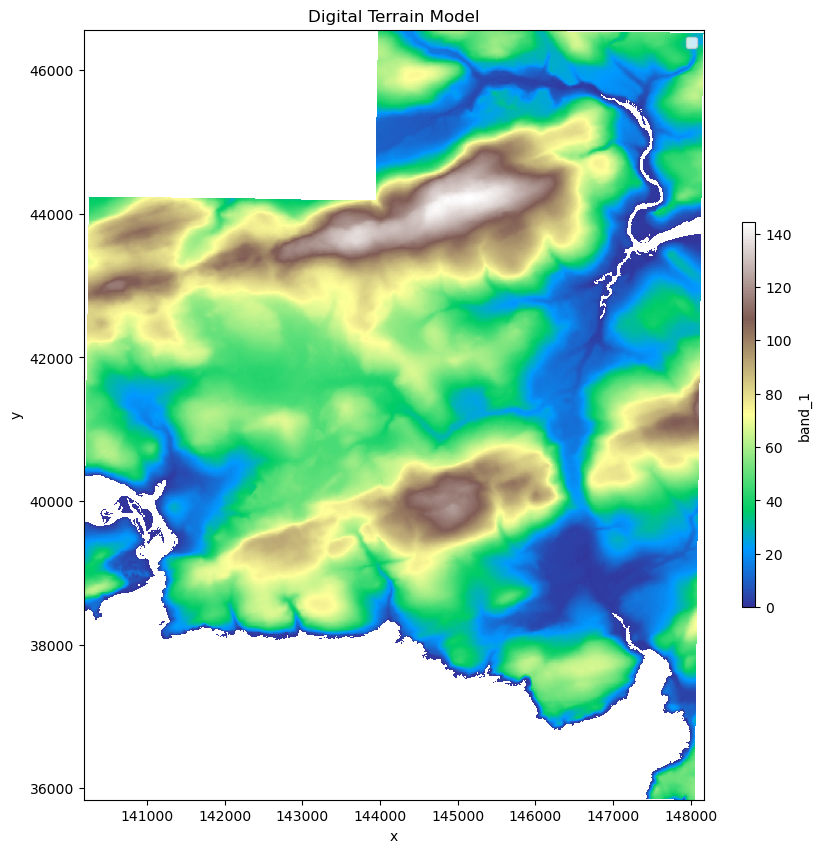

In [18]:
Path_Input_Dtm = os.path.join(Path_Root, Path_Julia, Filename_Input_DtmJulia)

Dtm = rxr.open_rasterio(Path_Input_Dtm, band_as_variable=True)
Dtm.raster.set_crs(Param_Crs)

if Flag_Plot:
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot()
    Dtm["band_1"].plot(
        ax=ax, cbar_kwargs=dict(aspect=30, shrink=0.5), vmin=0, cmap="terrain"
    )
    ax.set_title("Digital Terrain Model")
    ax.legend()


## == **Step 2:**  ***Deriving local drain direction or flow direction of bassin (LDD)*** ==

=== Burning rivers ====


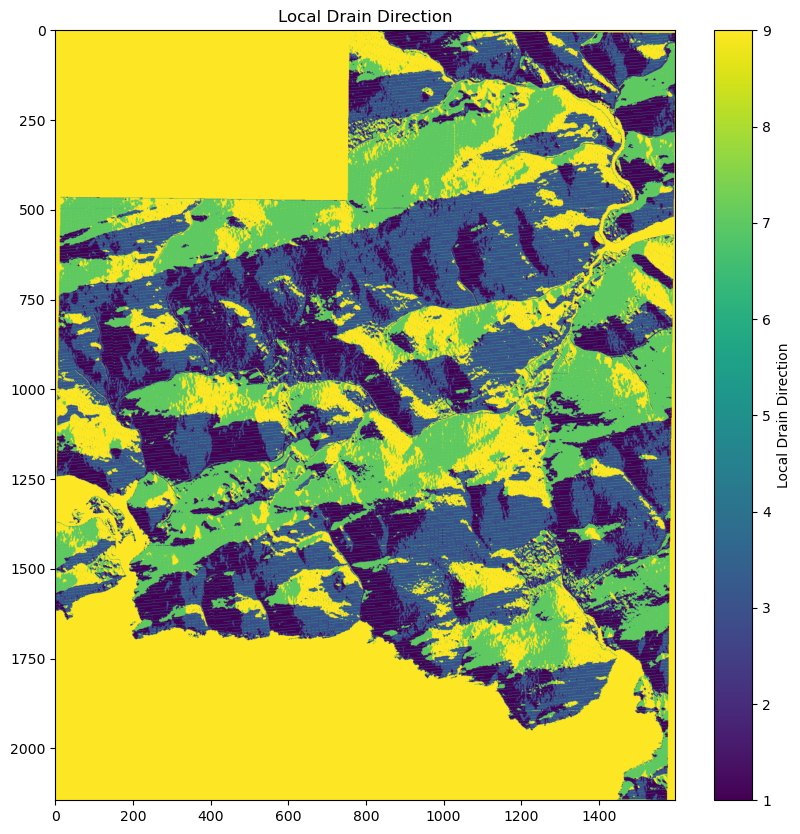

In [7]:
"""
https://deltares.github.io/hydromt/latest/_generated/hydromt.gis.flw.d8_from_dem.html#hydromt.gis.flw.d8_from_dem

        hydromt.gis.flw.d8_from_dem()

# Parameters:
da_elv (2D xarray.DataArray) – elevation raster

max_depth (float, optional) – Maximum pour point depth. Depressions with a larger pour point depth are set as pit. A negative value (default) equals an infinitely large pour point depth causing all depressions to be filled.

outlets ({'edge', 'min', 'idxs_pit'}) – Position of basin outlet(s) If ‘edge’ (default) all valid elevation edge cell are considered. If ‘min’ only the global minimum elevation edge cell is considered and all flow is directed to this cell. If ‘idxs_pit’ the linear indices of the outlet cells are provided in idxs_pit.

idxs_pit (1D array of int) – Linear indices of outlet cells.

gdf_riv (geopandas.GeoDataArray, optional) – River vector data. If provided, the river cells are burned into the dem. Different methods can be used to burn in the river cells, see riv_burn_method.

riv_burn_method ({'uparea', 'rivdph', 'fixed'}, optional) – Method to burn in river vector to aid the flow direction derivation, requires gdf_riv. If ‘fixed’ (default) a fixed river depth rivdph value is used to burn in the river cells. If ‘rivdph’ the rivdph column is used to burn in the river cells directly. If ‘uparea’ the uparea column is used to create a synthetic river depth based on max(1, log10(uparea[m2])).

riv_depth (float) – fixed depth value used to burn in the dem

**kwargs – Additional keyword arguments that are passed to the pyflwdir.dem.fill_depressions() function.

Returns
da_flw – D8 flow direction grid
"""

if Flag_BurnRiver:
    print("=== Burning rivers ====")

    Path_Input_River_Geojson = os.path.join(Path_Root_Data, Path_River, Filename_Input_RiverShp)

    River_Geopandas = gpd.read_file(Path_Input_River_Geojson)

    Ldd_Basins = hydromt.gis.flw.d8_from_dem(
        Dtm["band_1"],
        # max depression poir point depth; -1 means no local pits
        max_depth=Param_PitMaxDepth,
        # option: "edge" (default), "min", "idxs_pit"
        outlets="edge",
        idxs_pit=None,
        gdf_riv=River_Geopandas,  # user supplied river network to aid flow direction derivation
        # options: "fixed" (default), "rivdph", "uparea"
        riv_burn_method="fixed",
        # fixed river depth in meters, only used if riv_burn_method="fixed"
        riv_depth=Param_RiverDepth,
        # **kwargs to be passed to pyflwdir.dem.fill_depressions)
    )

else:
    # Derive flow directions with outlets at the edges -> this is the default
    Ldd_Basins = hydromt.gis.flw.d8_from_dem(
        Dtm["band_1"],
        # max depression poir point depth; -1 means no local pits
        max_depth=Param_PitMaxDepth,
        # option: "edge" (default), "min", "idxs_pit"
        outlets="edge",
        idxs_pit=None,
        gdf_riv=None,  # user supplied river network to aid flow direction derivation
        # options: "fixed" (default), "rivdph", "uparea"
        riv_burn_method="fixed",
        # riv_depth=5, # fixed river depth in meters, only used if riv_burn_method="fixed"
        # **kwargs to be passed to pyflwdir.dem.fill_depressions)
    )


# Convert the xr.DataArray to a flow direction raster object, which is used by the PyFlwDir package.
Flwdir = hydromt.gis.flw.flwdir_from_da(Ldd_Basins, ftype="d8")

# Converting D8-> Ldd as required by Wflow model.
Ldd_Basins = xarray.apply_ufunc(d8_to_ldd, Ldd_Basins.load())
Ldd_Basins.raster.set_crs(Param_Crs)


# Deriving raster dimensions
RasterFormat = Ldd_Basins.to_dataset(name=Filename_Ldd)
RasterFormat = RasterFormat.raster.gdal_compliant()  # update spatial metadata
Dims = RasterFormat.raster.dims

Attrs = dict(_FillValue=np.uint8(0), long_name="Local Drain Direction", units="-")
RasterFormat[Filename_Ldd] = xarray.Variable(Dims, Ldd_Basins, attrs=Attrs)
RasterFormat[Filename_Ldd] = RasterFormat[Filename_Ldd].raster.mask_nodata()

if Flag_Plot:
    PLOT_MAPS(RasterFormat[Filename_Ldd], "Local Drain Direction", 1, 9)


## == **Step 3:**  ***Deriving rivers*** ==

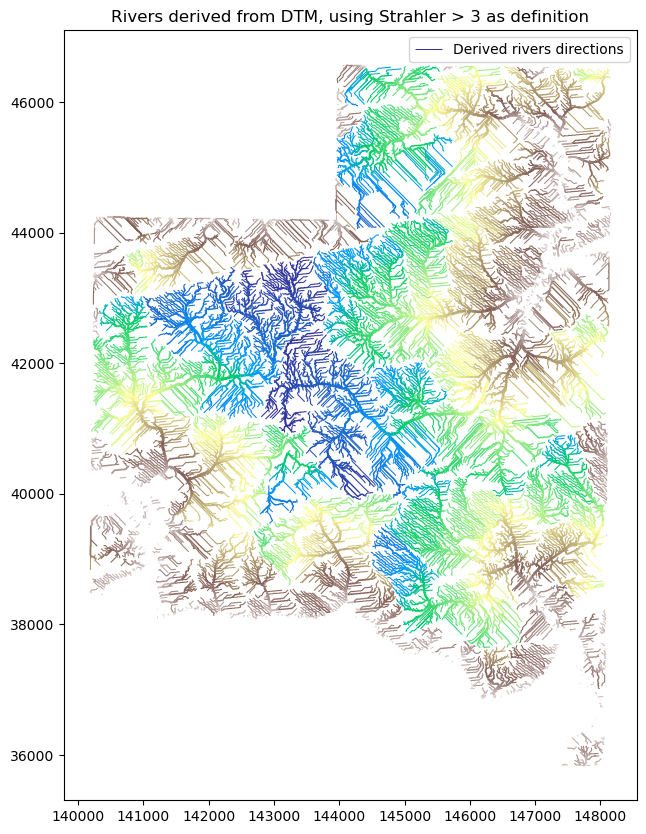

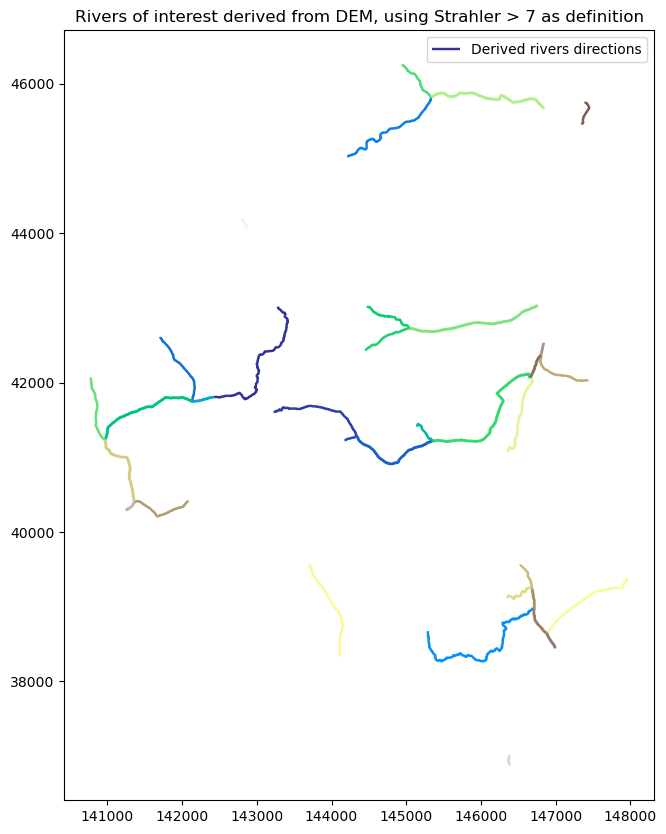

In [8]:
RiverOrder = Flwdir.stream_order()

# Saving
Attrs = dict(_FillValue=np.uint8(0), long_name="Stream Order", units="-")
RasterFormat[Filename_StreamOrder] = xarray.Variable(Dims, RiverOrder, attrs=Attrs)

if Flag_Plot:
    Rivers_RiverOrder_Plot = gpd.GeoDataFrame.from_features(Flwdir.streams(min_sto=3))
    Rivers_AllTrue_Plot = gpd.GeoDataFrame.from_features(Flwdir.streams(min_sto=7))
    # plot river network the derived new flow directions
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot()
    Rivers_RiverOrder_Plot.plot(
        ax=ax,
        cmap="terrain",
        linewidth=Rivers_RiverOrder_Plot["strord"] / 4,
        label="Derived rivers directions",
    )
    ax.set_title("Rivers derived from DTM, using Strahler > 3 as definition")
    ax.legend()

    # plot river network the derived new flow directions
    fig = plt.figure(figsize=(10, 10))
    ax_2 = fig.add_subplot()

    Rivers_AllTrue_Plot.plot(
        ax=ax_2,
        cmap="terrain",
        linewidth=Rivers_AllTrue_Plot["strord"] / 4,
        label="Derived rivers directions",
    )
    ax_2.set_title(
        "Rivers of interest derived from DEM, using Strahler > 7 as definition"
    )
    ax_2.legend()


## == **Step 4a:**  ***Bassins*** ==
## *For visualisation only, not an input for Wflow model*

Total number of outflow cells: 2105


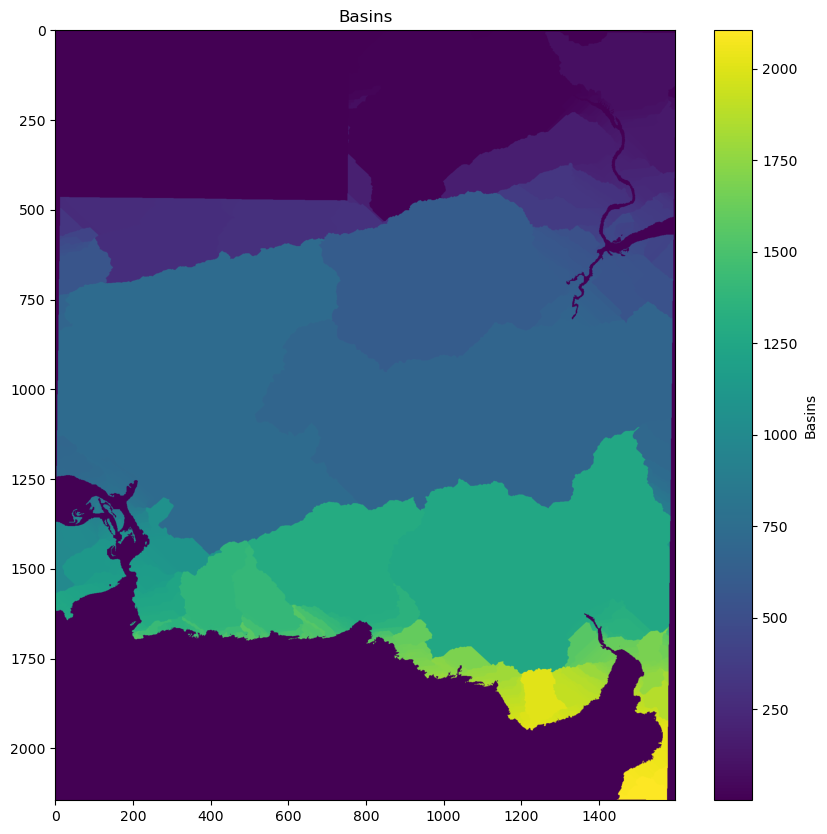

In [10]:
if Flag_BassinCatchment:
    Basins = Flwdir.basins(idxs=Flwdir.idxs_pit).astype(np.int32)
    N_Pits_Basins = np.sum(
   ~np.isnan(RasterFormat[Filename_Ldd].where(RasterFormat[Filename_Ldd] == 5))
   ).values
    print(
   f"Total number of outflow cells: {np.sum(~np.isnan(RasterFormat[Filename_Ldd].where(RasterFormat[Filename_Ldd] == 5))).values}"
   )

    RasterFormat["Basins"] = xarray.Variable(Dims, Basins, attrs=Attrs)
    RasterFormat["Basins"] = RasterFormat["Basins"].raster.mask_nodata()

    if Flag_Plot:
        PLOT_MAPS(Basins, "Basins", 1, N_Pits_Basins, Cmap="viridis")


## == **Step 4b:**  ***Catchment*** ==
.		*Not an input for Wflow model*


Cell SelectCatchmentId: 687.0


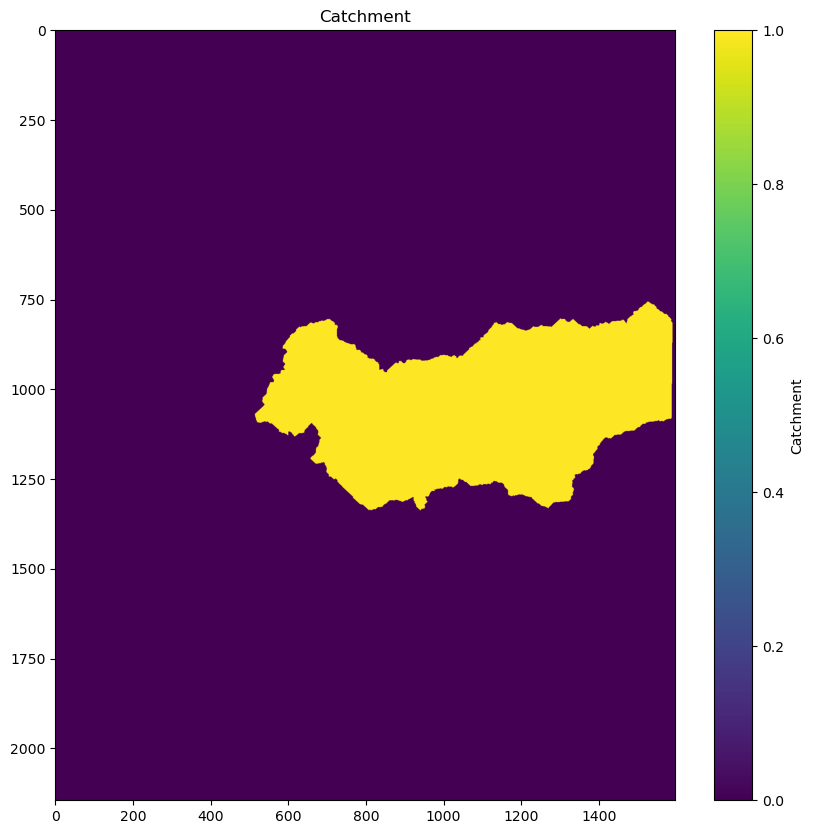

In [11]:
if Flag_BassinCatchment:
	Row, Col = Ldd_Basins.raster.rowcol(xs=Param_LatLong_Gauge[0], ys=Param_LatLong_Gauge[1])

	# Use isel to index by row (often named 'y') and column (often named 'x')
	SelectCatchmentId = RasterFormat["Basins"].isel(y=Row, x=Col).values

	print("Cell SelectCatchmentId:", SelectCatchmentId[0][0])
	Catchment = RasterFormat["Basins"] == SelectCatchmentId

if Flag_Plot:
	PLOT_MAPS(Catchment, "Catchment", 0, 1, Cmap="viridis")


## == **Step 4c:**  ***Subcatchment at an outlet*** ==

Outlet is on a river of Strord: 8


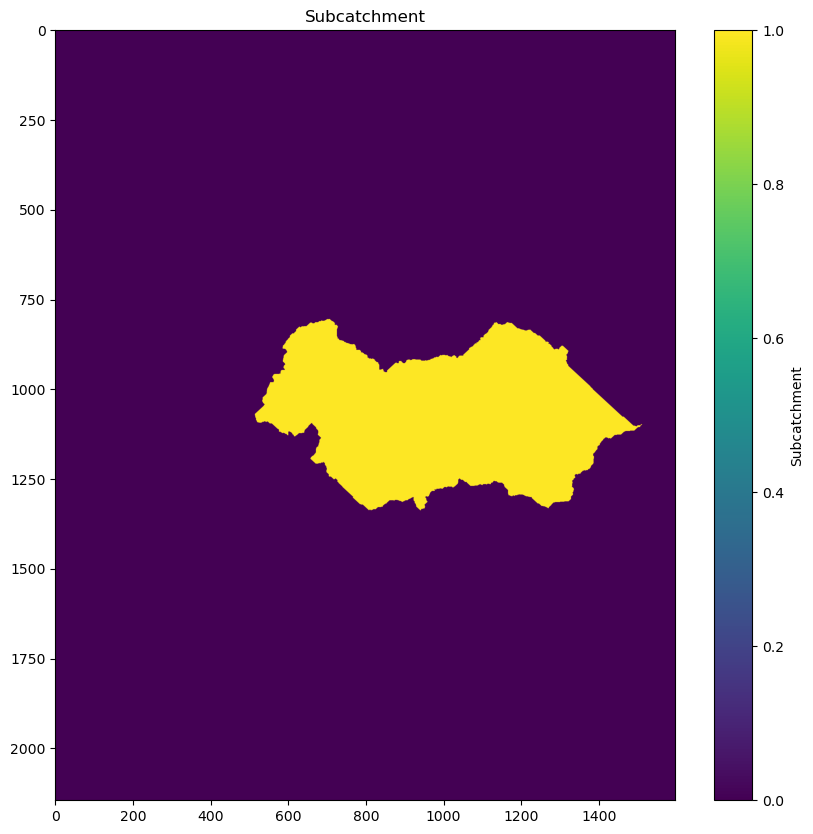

In [24]:
X, Y = np.array([Param_LatLong_Gauge[0]]), np.array([Param_LatLong_Gauge[1]])
Subcatchment = Flwdir.basins(xy=(X, Y)).astype(np.int32)

# # Check if
IsOuletOnRiver = RasterFormat[Filename_StreamOrder].isel(y=Row, x=Col).values
print("Outlet is on a river of Strord:", IsOuletOnRiver[0][0])

if IsOuletOnRiver[0][0] < 2:
   error("Error Outlet is not on a river check its coordinates")

Attrs = dict(_FillValue=np.uint8(0), long_name="Subcatchment", units="-")
RasterFormat[Filename_Subcatchment] = xarray.Variable(Dims, Subcatchment, attrs=Attrs)

if Flag_Plot:
    PLOT_MAPS(RasterFormat[Filename_Subcatchment], "Subcatchment", 0, 1, Cmap="viridis")


## == **Step 5:**  ***Correct Dtm*** ==
Hydrological corrected elevation based on Yamazaki et al. (2012)


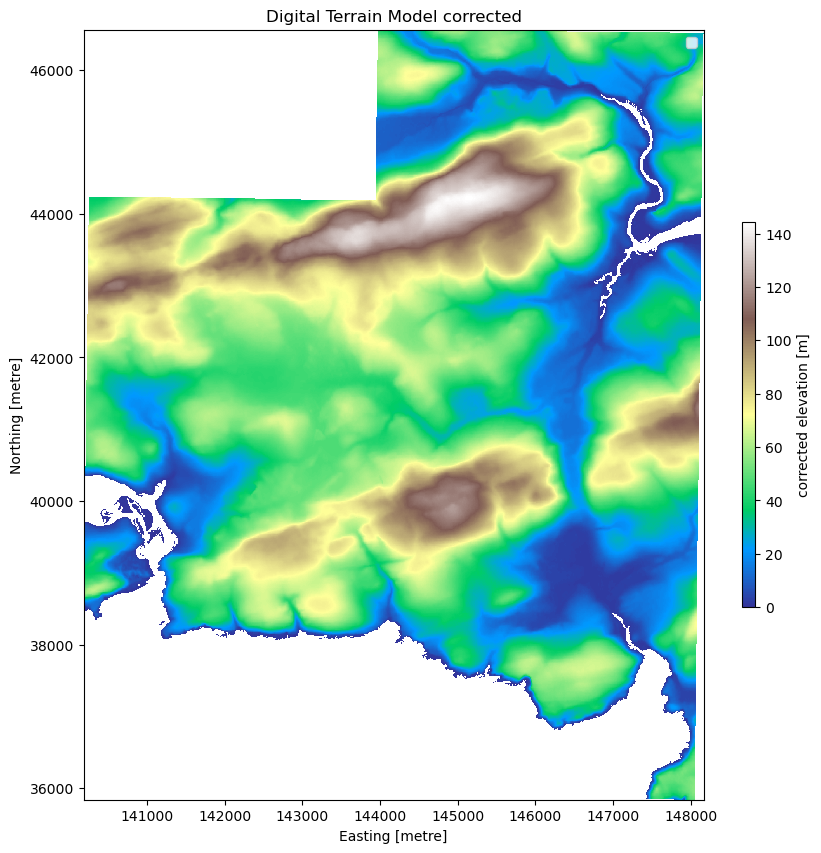

In [19]:
Dtm_Corrected = Flwdir.dem_adjust(elevtn=Dtm["band_1"].values)

# Saving Dtm
Attrs = dict(_FillValue=np.nan, long_name="corrected elevation", units="m")
RasterFormat[Filename_DtmCorrected] = xarray.Variable(Dims, Dtm_Corrected, attrs=Attrs)
# RasterFormat[Filename_DtmCorrected] = RasterFormat[Filename_DtmCorrected].raster.mask_nodata()

if Flag_Plot:
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot()
    RasterFormat[Filename_DtmCorrected].plot(
        ax=ax, cbar_kwargs=dict(aspect=30, shrink=0.5), vmin=0, cmap="terrain"
    )
    ax.set_title("Digital Terrain Model corrected")
    ax.legend()


## == **Step 4:**  ***Slope*** ==

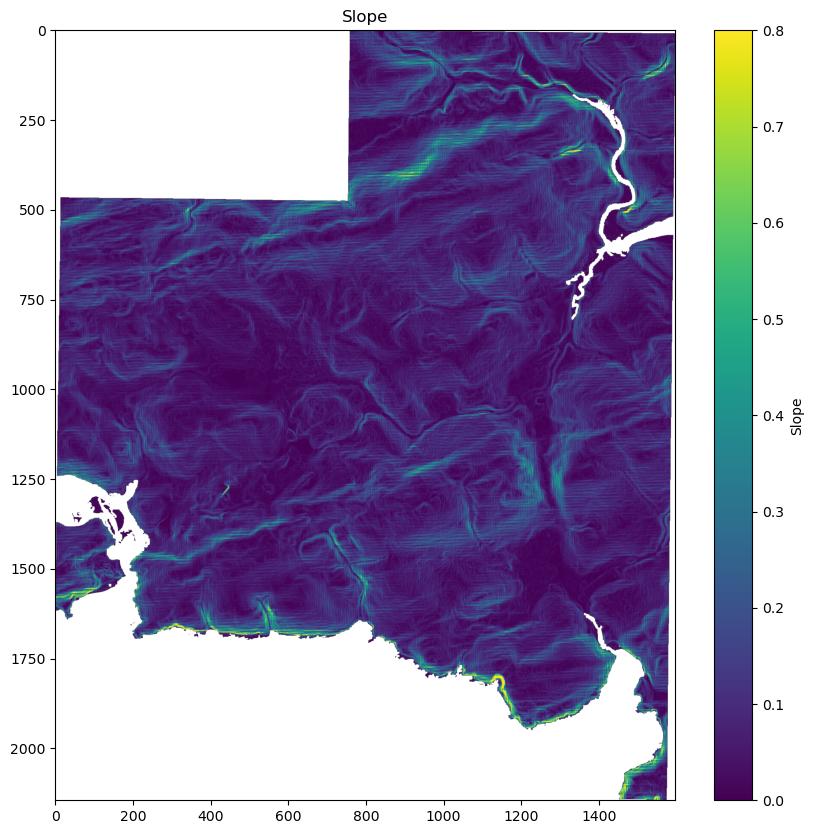

In [14]:
Slope = pyflwdir.dem.slope(
    elevtn=RasterFormat[Filename_DtmCorrected].values,
    nodata=RasterFormat[Filename_DtmCorrected].raster.nodata,
    # True if geographic crs, False if projected crs
    latlon=RasterFormat[Filename_DtmCorrected].raster.crs.is_geographic,
    transform=RasterFormat[Filename_DtmCorrected].raster.transform,
)

Attrs = dict(_FillValue=np.nan, long_name=Filename_Slope, units="m/m")
RasterFormat[Filename_Slope] = xarray.Variable(Dims, Slope, attrs=Attrs)
RasterFormat[Filename_Slope] = RasterFormat[Filename_Slope].raster.mask_nodata()

if Flag_Plot:
    PLOT_MAPS(RasterFormat[Filename_Slope], "Slope", 0.0, 0.8)


## == **Step 5:** *River length* ==

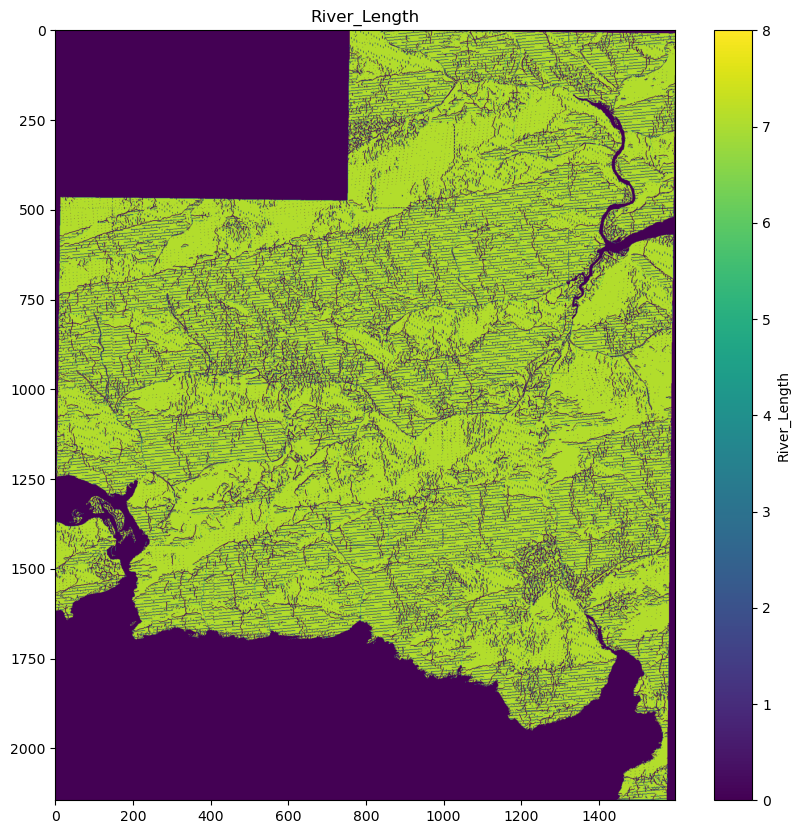

In [15]:
River_Length = Flwdir.subgrid_rivlen(idxs_out=None, mask=None, direction="up", unit="m")

# Saving Dtm
Attrs = dict(_FillValue=np.nan, long_name="River Length", units="m")
RasterFormat[Filename_RiverLength] = xarray.Variable(Dims, River_Length, attrs=Attrs)
RasterFormat[Filename_RiverLength] = RasterFormat[Filename_RiverLength].raster.mask_nodata()

if Flag_Plot:
    PLOT_MAPS(
        RasterFormat[Filename_RiverLength], "River_Length", 0.0, 8, Cmap="viridis"
    )


## == **Step 6:** *Flood plains* ==

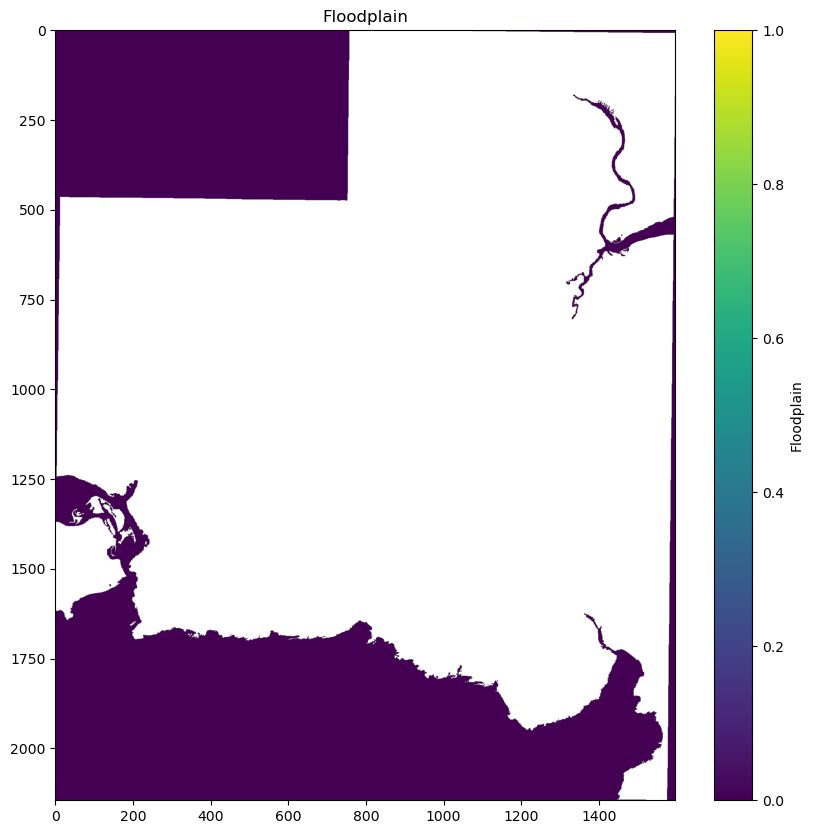

In [16]:
Floodplain = Flwdir.floodplains(Dtm_Corrected)

# Saving flood plain
Attrs = dict(_FillValue=np.bool(False), long_name="Flood Plains", units="m")
RasterFormat[Filename_Floodplains] = xarray.Variable(Dims, Floodplain, attrs=Attrs)
RasterFormat[Filename_Floodplains] = RasterFormat[
    Filename_Floodplains].raster.mask_nodata()

if Flag_Plot:
    PLOT_MAPS(RasterFormat[Filename_Floodplains], "Floodplain", 0, 1)


In [ ]:
RasterFormat[Filename_DtmCorrected]

Nx, Ny = np.shape(RasterFormat[Filename_DtmCorrected])


for iX in range(Nx):
   for iY in range(Ny):
		if RasterFormat[Filename_DtmCorrected] < 1:
      	Map[iX, iY] = np.nan

#  # Write to tiff file
#  prof.update(dtype=Map.dtype, nodata=False)
#  with rasterio.open(Path_Output, "w", **prof) as src:
#      src.write(Map, 1)


SyntaxError: incomplete input (1956007760.py, line 14)

## == **Step 7:** *Saving to file* ==

In [25]:

Path = os.path.join(Path_Root, Path_Python)
# export the hydrography data as tif files (one per variable)

RasterFormat.raster.to_mapstack(
    root=Path, driver="GTiff")



# =========================================================================================================